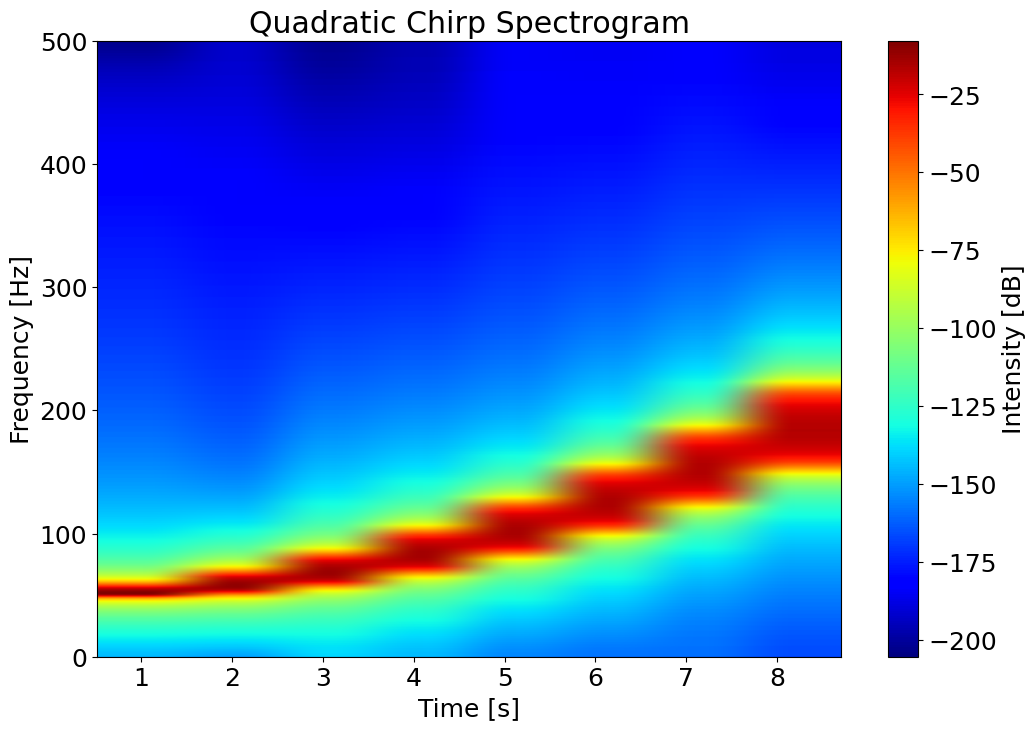

In [8]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams.update({'font.size': 18})

dt = 0.001
t = np.arange(0, 10, dt)  # 10 seconds
f0 = 50
f1 = 250
t1 = 10
x = np.cos(2 * np.pi * t * (f0 + (f1 - f0) * np.power(t, 2) / (3 * t1 ** 2)))

# Improved spectrogram parameters
plt.specgram(x, NFFT=2048, Fs=1/dt, noverlap=1024, cmap='jet', scale='dB', mode='psd')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.title('Quadratic Chirp Spectrogram')
plt.colorbar(label='Intensity [dB]')
plt.ylim([0, 500])
plt.show()

In [10]:
from IPython.display import Audio
Audio(x, rate=int(1/dt))

### Spectrogram Explanation

The spectrogram visualizes how the frequency content of the signal changes over time. In the plot:
- **Horizontal axis (x-axis):** Time (seconds)
- **Vertical axis (y-axis):** Frequency (Hz)
- **Color intensity:** Represents the signal's power at each time and frequency.
    - **Red/yellow regions:** High intensity (loud/strong frequencies)
    - **Blue regions:** Low intensity (quiet/weak frequencies)

For a quadratic chirp, you should see the frequency increasing nonlinearly over time, with the strongest (red/yellow) band tracing the main frequency component as it sweeps upward.

#### What do the dB values mean in the spectrogram?

- The colorbar shows intensity in decibels (dB), a logarithmic measure of signal power.
- The dB value is calculated as:
  $$
  \text{dB} = 10 \cdot \log_{10}\left(\frac{P}{P_{ref}}\right)
  $$
  where $P$ is the power at a point, and $P_{ref}$ is a reference (usually the maximum power in the spectrogram).
- **-25 dB (red):** Very strong signal, close to the maximum power.
- **-175 dB (blue):** Extremely weak signal, about $10^{15}$ times weaker than the maximum.
- dB values are negative when the power is less than the reference.
- The log scale allows you to see both strong and faint features together in the same plot.

#### Why Use a Log Scale for the Spectrogram?

The spectrogram uses a logarithmic (dB) scale for intensity (colorbar):
- **Logarithmic scale (dB):** Shows the ratio of signal power on a log scale, making it easier to see both strong and weak frequency components in the same plot.
- **Benefits:**
    - Human hearing perceives loudness logarithmically, so a log scale matches our perception.
    - Weak signals that would be invisible on a linear scale become visible.
    - Makes it easier to compare relative strengths of different frequencies.
- **Interpretation:**
    - Each color step represents a fixed ratio (e.g., 10x) change in intensity, not a fixed linear amount.
    - Red/yellow = high intensity (loud), blue = low intensity (quiet), but the difference between colors is multiplicative, not additive.

This helps you see both the main chirp and any faint background noise or harmonics.